# 01 - Data exploration

**Owner:** Member 1
**Task:** Part A describes the raw data of KuaiRand-Pure and KuaiRec (files, columns, example rows, feedback, users, videos, how the unbiased part was collected). Part B gives what the models see after filtering: split sizes including the unbiased test sets, split checks, degree distributions, the positive definitions, duplicates, and how popular the biased and unbiased test positives are.
**Inputs:** raw files under `data/`, src/data.py, src/train.py (`evaluate`)
**Outputs:** results/01_data_stats.json, results/01_dataset_overview.csv, results/01_degree_distributions.png, results/01_kuairand_daily.png

MovieLens-100K is used only for smoke tests (notebook 02) and is not described here.

In [1]:
import os, sys, json
sys.path.insert(0, os.path.abspath(os.path.join(os.getcwd(), "..", "src")))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import zipfile
import torch
import data
import train

SEEDS = [0, 1, 2]
RESULTS_DIR = os.path.abspath(os.path.join(os.getcwd(), "..", "results"))
os.makedirs(RESULTS_DIR, exist_ok=True)

pd.set_option("display.max_columns", 40, "display.width", 200, "display.max_colwidth", None, "display.float_format", "{:,.3f}".format)

def share_table(series, name):
    """Counts and shares of a categorical column."""
    counts = series.value_counts(dropna=False)
    return pd.DataFrame({name: counts.index, "count": counts.values, "share": counts.values / counts.sum()})

# Part A: the raw data

## A1. KuaiRand-Pure

Interaction logs from Kuaishou, a short-video app (Gao et al., CIKM 2022). Each row is one **exposure**: a video was shown to a user, and the row records what the user did with it. Two things matter for this project:

- **Feedback is behaviour, not a rating.** There are several signals per exposure (click, like, follow, comment, forward, hate, long view) and the watch time.
- **Part of the exposure is random.** Normally the platform's own recommender decides what each user sees, so the log mostly contains videos the system already believed the user would like (*exposure bias*). For about two weeks the authors inserted **uniformly random videos** into the feed. Feedback on those videos is free of that bias, which lets us test a model on items the platform would not have chosen.

| File | Content | Used by us |
|---|---|---|
| `log_standard_4_08_to_4_21_pure.csv` | Exposures chosen by the platform recommender, 9 to 21 April 2022 (the file name says 8 April, the first row is 9 April) | yes (train, val, test) |
| `log_standard_4_22_to_5_08_pure.csv` | Same, 22 April to 8 May 2022 | yes (train, val, test) |
| `log_random_4_22_to_5_08_pure.csv` | Randomly exposed videos, 22 April to 8 May 2022 | yes (unbiased test set only) |
| `user_features_pure.csv` | Activity level, follower ranges, registration age, anonymous features | only for the description below |
| `video_features_basic_pure.csv` | Author, type, upload date, duration, tag | only for the description below |
| `video_features_statistic_pure.csv` | Platform-wide counters per video | no |

**Columns of a log row**

| Column | Meaning |
|---|---|
| `user_id`, `video_id` | Who was shown what |
| `date`, `hourmin`, `time_ms` | When |
| `is_click` | The user clicked the video (our positive) |
| `is_like`, `is_follow`, `is_comment`, `is_forward`, `is_hate` | Explicit reactions |
| `long_view` | The platform's long-view flag (watch time above its threshold) |
| `play_time_ms`, `duration_ms` | Watch time and video length |
| `profile_stay_time`, `comment_stay_time`, `is_profile_enter` | Time on the author's profile and in the comments |
| `is_rand` | 1 if the video was randomly exposed |
| `tab` | Part of the app where the exposure happened |

In [2]:
names = {"standard 04-09..04-21": data.KUAI_STANDARD[0], "standard 04-22..05-08": data.KUAI_STANDARD[1], "random 04-22..05-08": data.KUAI_RANDOM}
logs = pd.concat([pd.read_csv(os.path.join(data.KUAI_DIR, f)).assign(log=k) for k, f in names.items()], ignore_index=True)
logs["exposure"] = np.where(logs.is_rand == 1, "random", "standard")

def overview(g):
    return pd.Series(dict(rows=len(g), users=g.user_id.nunique(), videos=g.video_id.nunique(),
                          first_day=str(g.date.min()), last_day=str(g.date.max()), random_share=g.is_rand.mean(),
                          rows_per_user=len(g) / g.user_id.nunique(), click_rate=g.is_click.mean()))

kuai_overview = pd.concat([logs.groupby("log", sort=False).apply(overview, include_groups=False),
                           overview(logs).to_frame("all logs").T])
kuai_overview

,rows,users,videos,first_day,last_day,random_share,rows_per_user,click_rate
standard 04-09..04-21,1141112,26210,7538,20220409,20220421,0.000,43.537,0.463
standard 04-22..05-08,295497,25877,6618,20220422,20220508,0.000,11.419,0.445
random 04-22..05-08,1186059,27285,7583,20220422,20220508,1.000,43.469,0.176
all logs,2622668,27285,7583,20220409,20220508,0.452,96.121,0.331


### What one row looks like

In [3]:
logs.drop(columns=["log", "exposure"]).sample(8, random_state=0).reset_index(drop=True)

,user_id,video_id,date,hourmin,time_ms,is_click,is_like,is_follow,is_comment,is_forward,is_hate,long_view,play_time_ms,duration_ms,profile_stay_time,comment_stay_time,is_profile_enter,is_rand,tab
0,15518,5878,20220427,2000,1651060579872,0,0,0,0,0,0,0,1088,52400,0,0,0,1,1
1,25185,232,20220410,700,1649545931436,0,0,0,0,0,0,0,0,64166,0,0,0,0,1
2,24182,5603,20220417,900,1650158779979,1,0,0,0,0,0,1,25392,283783,0,0,0,0,1
3,12594,1331,20220504,1700,1651656562891,0,0,0,0,0,0,0,821,103380,0,0,0,1,1
4,15350,3647,20220416,1000,1650074472631,1,0,0,0,0,0,0,8163,45040,0,0,0,0,1
5,23453,3328,20220412,2300,1649775085447,0,0,0,0,0,0,0,0,380080,0,0,0,0,0
6,5102,3163,20220507,1700,1651916041781,0,0,0,0,0,0,0,1320,82566,0,0,0,1,1
7,4346,3844,20220412,1600,1649753327555,0,0,0,0,0,0,0,1286,114416,0,0,0,0,1


### Feedback signals
Rate per exposure. Clicks are common; likes, follows, comments and forwards are rare. Every positive signal is much rarer on randomly exposed videos, because the platform recommender shows users what they tend to like and a random video usually is not that. The one negative signal, `is_hate`, goes the other way and is about twice as frequent on random videos.

In [4]:
SIGNALS = ["is_click", "long_view", "is_like", "is_follow", "is_comment", "is_forward", "is_profile_enter", "is_hate"]
signal_table = pd.DataFrame({"standard count": logs[logs.exposure == "standard"][SIGNALS].sum(),
                             "standard rate": logs[logs.exposure == "standard"][SIGNALS].mean(),
                             "random count": logs[logs.exposure == "random"][SIGNALS].sum(),
                             "random rate": logs[logs.exposure == "random"][SIGNALS].mean()})
signal_table["random / standard"] = signal_table["random rate"] / signal_table["standard rate"]
signal_table.style.format({"standard count": "{:,.0f}", "random count": "{:,.0f}", "standard rate": "{:.3%}",
                           "random rate": "{:.3%}", "random / standard": "{:.2f}"})

,standard count,standard rate,random count,random rate,random / standard
is_click,"660,342",45.965%,"208,934",17.616%,0.38
long_view,"476,724",33.184%,"100,769",8.496%,0.26
is_like,"26,546",1.848%,"5,691",0.480%,0.26
is_follow,"1,543",0.107%,310,0.026%,0.24
is_comment,"3,657",0.255%,411,0.035%,0.14
is_forward,"1,382",0.096%,402,0.034%,0.35
is_profile_enter,"34,496",2.401%,"6,597",0.556%,0.23
is_hate,710,0.049%,"1,351",0.114%,2.30


How the signals relate: of the exposures with one signal (row), the share that also has another (column).

In [5]:
core = ["is_click", "long_view", "is_like"]
pd.DataFrame({b: [logs.loc[logs[a] == 1, b].mean() for a in core] for b in core}, index=[f"given {a}" for a in core]).style.format("{:.1%}")

,is_click,long_view,is_like
given is_click,100.0%,66.2%,3.0%
given long_view,99.6%,100.0%,3.5%
given is_like,80.4%,62.2%,100.0%


### Watch time
Play time and video length in seconds. A play time of 0 means the video was shown but not played.

In [6]:
logs["play_s"], logs["duration_s"] = logs.play_time_ms / 1000, logs.duration_ms / 1000
watch = logs.groupby("exposure").agg(exposures=("play_s", "size"), not_played_share=("play_s", lambda s: (s == 0).mean()),
                                      median_play_s=("play_s", "median"), mean_play_s=("play_s", "mean"),
                                      median_duration_s=("duration_s", "median"))
watch["median_play_s_if_clicked"] = logs[logs.is_click == 1].groupby("exposure").play_s.median()
watch

,exposures,not_played_share,median_play_s,mean_play_s,median_duration_s,median_play_s_if_clicked
exposure,,,,,,
random,1186059,0.007,2.091,6.936,76.833,14.982
standard,1436609,0.132,4.904,22.893,70.200,27.569


### Exposures over time
The random log covers only the second period and sits on top of the standard feed.

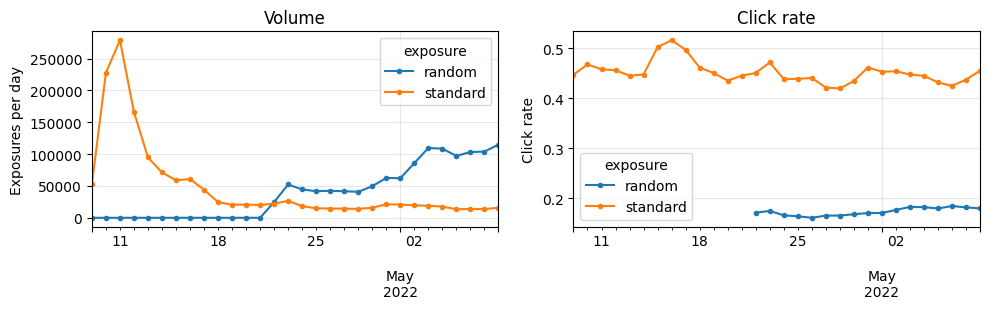

days  exposures  clicks  click_rate
period         exposure                                     
9-21 April     standard    13    1141112  528845       0.463
22 April-8 May standard    17     295497  131497       0.445
               random      17    1186059  208934       0.176

In [7]:
daily = logs.groupby(["date", "exposure"]).size().unstack(fill_value=0)
daily.index = pd.to_datetime(daily.index.astype(str), format="%Y%m%d")
clicks = logs.groupby(["date", "exposure"]).is_click.mean().unstack()
clicks.index = daily.index

fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
daily.plot(ax=axes[0], marker="o", ms=3)
axes[0].set_ylabel("Exposures per day"); axes[0].set_title("Volume")
clicks.plot(ax=axes[1], marker="o", ms=3)
axes[1].set_ylabel("Click rate"); axes[1].set_title("Click rate")
for ax in axes:
    ax.set_xlabel(""); ax.grid(alpha=0.3); ax.legend(title="exposure")
fig.tight_layout()
fig.savefig(os.path.join(RESULTS_DIR, "01_kuairand_daily.png"), dpi=200, metadata={"Software": None})
plt.show()

periods = logs.assign(period=np.where(logs.date <= 20220421, "9-21 April", "22 April-8 May")).groupby(["period", "exposure"], sort=False).agg(
    days=("date", "nunique"), exposures=("is_click", "size"), clicks=("is_click", "sum"), click_rate=("is_click", "mean"))
periods

### Users and videos in the logs
Exposures and clicks per user and per video.

In [8]:
def per_entity(col):
    rows = {}
    for exp, g in logs.groupby("exposure"):
        rows[(exp, "exposures")] = g.groupby(col).size().describe()
        rows[(exp, "clicks")] = g[g.is_click == 1].groupby(col).size().describe()
    return pd.DataFrame(rows).T.round(1)

display(per_entity("user_id"))
per_entity("video_id")

count   mean    std    min    25%    50%    75%       max
random   exposures 27,285.000 43.500 63.900 10.000 14.000 22.000 45.000 1,580.000
         clicks    22,855.000  9.100 14.600  1.000  2.000  4.000 10.000   358.000
standard exposures 27,077.000 53.100 50.800  1.000 18.000 39.000 72.000   910.000
         clicks    26,591.000 24.800 22.900  1.000  8.000 18.000 35.000   237.000

count    mean     std   min     25%     50%     75%        max
random   exposures 7,583.000 156.400  30.800 1.000 152.000 162.000 171.000    214.000
         clicks    7,485.000  27.900  14.500 1.000  17.000  26.000  36.000    106.000
standard exposures 7,551.000 190.300 437.800 1.000  21.000  57.000 177.000 10,424.000
         clicks    7,218.000  91.500 243.700 1.000   6.000  21.000  76.000  5,992.000

How much the two kinds of exposure overlap. Most users appear in both logs, which is what makes the unbiased test set possible.

In [9]:
std, rnd = logs[logs.exposure == "standard"], logs[logs.exposure == "random"]
std_pos, rnd_pos = std[std.is_click == 1], rnd[rnd.is_click == 1]

def overlap(col):
    a, b, ap, bp = (set(x[col]) for x in (std, rnd, std_pos, rnd_pos))
    return {"in standard": len(a), "in random": len(b), "in both": len(a & b),
            "clicked in standard": len(ap), "clicked in random": len(bp), "clicked in both": len(ap & bp)}

pd.DataFrame({"users": overlap("user_id"), "videos": overlap("video_id")}).T

,in standard,in random,in both,clicked in standard,clicked in random,clicked in both
users,27077,27285,27077,26591,22855,22335
videos,7551,7583,7551,7218,7485,7124


### Where in the app
`tab` is the part of the app in which the video was shown.

In [10]:
tab = logs.groupby(["tab", "exposure"]).agg(exposures=("is_click", "size"), click_rate=("is_click", "mean")).unstack()
tab.columns = [f"{b} {a}" for a, b in tab.columns]
tab["share of all exposures"] = (tab.filter(like="exposures").sum(axis=1) / len(logs))
tab.sort_values("share of all exposures", ascending=False).head(8)

,random exposures,standard exposures,random click_rate,standard click_rate,share of all exposures
tab,,,,,
1,"1,178,025.000","1,058,389.000",0.177,0.523,0.853
0,NaN,"178,087.000",NaN,0.091,0.068
4,NaN,"93,165.000",NaN,0.615,0.036
2,764.000,"48,364.000",0.114,0.480,0.019
6,NaN,"42,785.000",NaN,0.176,0.016
11,"6,755.000",725.000,0.000,0.000,0.003
5,NaN,"4,169.000",NaN,0.278,0.002
3,NaN,"4,014.000",NaN,0.022,0.002


### User features
The platform's own activity label and how users with each label behave in our logs. The models do not use these features.

In [11]:
user_feat = pd.read_csv(os.path.join(data.KUAI_DIR, "user_features_pure.csv"))
display(user_feat.iloc[:, :13].head(5))

per_user = std.groupby("user_id").agg(exposures=("is_click", "size"), clicks=("is_click", "sum")).reset_index().merge(user_feat, on="user_id")
label = per_user.groupby("user_active_degree").agg(users=("user_id", "size"), exposures_per_user=("exposures", "mean"), clicks_per_user=("clicks", "mean"))
label["share_of_users"] = label.users / label.users.sum()
display(label.sort_values("users", ascending=False))

pd.concat({c: share_table(user_feat[c], "value").set_index("value") for c in
           ["register_days_range", "follow_user_num_range", "fans_user_num_range"]}).rename_axis(["feature", "value"])

,user_id,user_active_degree,is_lowactive_period,is_live_streamer,is_video_author,follow_user_num,follow_user_num_range,fans_user_num,fans_user_num_range,friend_user_num,friend_user_num_range,register_days,register_days_range
0,0,full_active,0,1,1,514,500+,150,"[100,1k)",34,"[30,60)",799,730+
1,1,full_active,0,-124,1,457,"(250,500]",20,"[10,100)",3,"[1,5)",1474,730+
2,2,full_active,0,-124,1,8,"(0,10]",26,"[10,100)",3,"[1,5)",231,181-365
3,3,full_active,0,1,1,91,"(50,100]",2166,"[1k,5k)",14,"[5,30)",2145,730+
4,4,full_active,0,-124,1,261,"(250,500]",10,"[10,100)",4,"[1,5)",764,730+


,users,exposures_per_user,clicks_per_user,share_of_users
user_active_degree,,,,
full_active,17871,60.146,26.550,0.660
high_active,6089,38.079,19.386,0.225
middle_active,2107,40.472,21.842,0.078
2_14_day_new,628,52.742,24.863,0.023
low_active,285,24.130,13.796,0.011
single_low_active,66,45.136,22.939,0.002
30day_retention,14,53.714,25.214,0.001
day_new,11,57.000,28.818,0.000
UNKNOWN,6,41.500,11.500,0.000


count  share
feature               value                     
register_days_range   730+          20063  0.735
                      366-730        3475  0.127
                      181-365        1778  0.065
                      91-180         1048  0.038
                      61-90           394  0.014
                      31-60           381  0.014
                      15-30           145  0.005
                      8-14              1  0.000
follow_user_num_range 500+           5950  0.218
                      (10,50]        4904  0.180
                      (250,500]      4377  0.160
                      (50,100]       4004  0.147
                      (150,250]      3490  0.128
                      (100,150]      2633  0.096
                      (0,10]         1739  0.064
                      0               188  0.007
fans_user_num_range   [10,100)      10467  0.384
                      [100,1k)       8664  0.318
                      [1,10)         5326  0.195
                      [1k,5k)        1460  0.054
                      0              1157  0.042
                      [5k,1w)         112  0.004
                      [1w,10w)         85  0.003
                      [10w,100w)       12  0.000
                      [100w,1000w)      2  0.000

### Video features

In [12]:
video_feat = pd.read_csv(os.path.join(data.KUAI_DIR, "video_features_basic_pure.csv"))
display(video_feat.head(5))
display(pd.DataFrame([dict(videos=len(video_feat), authors=video_feat.author_id.nunique(), tags=video_feat.tag.nunique(),
                           first_upload=video_feat.upload_dt.min(), last_upload=video_feat.upload_dt.max())], index=["catalogue"]))
display(share_table(video_feat.video_type, "video_type"))
display(share_table(video_feat.upload_type, "upload_type").head(8))

video_feat["duration_s"] = video_feat.video_duration / 1000
length = pd.cut(video_feat.duration_s, [0, 10, 30, 60, 120, 1e9], labels=["<10 s", "10-30 s", "30-60 s", "1-2 min", ">2 min"])
per_video = std.groupby("video_id").agg(exposures=("is_click", "size"), click_rate=("is_click", "mean")).reset_index().merge(
    video_feat.assign(length=length), on="video_id")
by_length = per_video.groupby("length", observed=True).agg(videos=("video_id", "size"), exposures=("exposures", "sum"), mean_click_rate=("click_rate", "mean"))
by_length["share_of_videos"] = by_length.videos / by_length.videos.sum()
by_length

,video_id,author_id,video_type,upload_dt,upload_type,visible_status,video_duration,server_width,server_height,music_id,music_type,tag
0,0,7349781,NORMAL,2022-04-10,LongImport,0.000,"87,433.000",720.000,"1,280.000",9155697141,9.000,39
1,1,2103883,NORMAL,2022-04-10,Kmovie,0.000,"218,066.000",720.000,"1,280.000",6355810746,9.000,2
2,2,5067285,NORMAL,2022-04-09,ShortImport,0.000,"9,233.000",720.000,"1,280.000",6618412736,4.000,1
3,3,7048760,NORMAL,2022-04-11,Web,0.000,"16,433.000",720.000,"1,280.000",9161677205,9.000,7
4,4,8635271,NORMAL,2022-04-09,Web,0.000,"38,766.000",720.000,"1,280.000",9141092381,9.000,9


,videos,authors,tags,first_upload,last_upload
catalogue,7583,6510,110,2022-04-09,2022-04-11


,video_type,count,share
0,NORMAL,7506,0.990
1,AD,76,0.010
2,UNKNOWN,1,0.000


,upload_type,count,share
0,LongImport,2925,0.386
1,Web,2416,0.319
2,ShortImport,917,0.121
3,Kmovie,879,0.116
4,LongPicture,143,0.019
5,UNKNOWN,80,0.011
6,PictureSet,73,0.010
7,LongCamera,64,0.008


,videos,exposures,mean_click_rate,share_of_videos
length,,,,
<10 s,281,65880,0.299,0.038
10-30 s,1456,317678,0.350,0.199
30-60 s,1068,218038,0.389,0.146
1-2 min,2096,377020,0.397,0.287
>2 min,2413,429119,0.382,0.330


## A2. KuaiRec

Also from Kuaishou, collected 5 July to 5 September 2020 (Gao et al., CIKM 2022). It has two parts:

- **Big matrix:** ordinary logs. Videos reached users through the platform recommender, so they carry the same exposure bias as KuaiRand's standard logs.
- **Small matrix:** for 1,411 users and a fixed block of 3,327 videos, the authors exposed *every* video to *every* user (99.6% of the pairs are filled; the rest are videos a user had blocked). Here nothing is missing because of the recommender, so it is an unbiased test set of a different kind from KuaiRand's random exposure.

There is no click or like. Each row is a play, and the feedback is the **watch ratio** = play time / video length. It can exceed 1 when the user replays the video. We call a pair positive when the user watched at least twice the video length (`watch_ratio >= 2`) in at least one play.

| File (inside `KuaiRec.zip`) | Content | Used by us |
|---|---|---|
| `big_matrix.csv` | 12.5M plays, 7,176 users, 10,728 videos | yes (train, val, test) |
| `small_matrix.csv` | 4.7M plays, 1,411 users x 3,327 videos | yes (unbiased test set only) |
| `user_features.csv`, `item_categories.csv`, `item_daily_features.csv`, `kuairec_caption_category.csv`, `social_network.csv` | Side information | no |

**Columns of a play**

| Column | Meaning |
|---|---|
| `user_id`, `video_id` | Who watched what |
| `play_duration`, `video_duration` | Watch time and video length, in milliseconds |
| `watch_ratio` | play_duration / video_duration |
| `time`, `date`, `timestamp` | When |

The loader reads the two CSV files straight from the zip archive, so it does not need to be extracted.

In [13]:
cols = ["user_id", "video_id", "play_duration", "video_duration", "date", "watch_ratio"]
types = {"user_id": "int32", "video_id": "int32", "play_duration": "int64", "video_duration": "int64", "watch_ratio": "float32"}
with zipfile.ZipFile(data.KUAIREC_ZIP) as z:
    rec = {m: pd.read_csv(z.open(data.KUAIREC_FILES + f"{m}_matrix.csv"), usecols=cols, dtype=types) for m in ("big", "small")}
for m in rec.values():
    m["date"] = m.date.fillna(0).astype("int32")

def matrix_overview(m):
    pairs = len(m.drop_duplicates(["user_id", "video_id"]))
    users, videos = m.user_id.nunique(), m.video_id.nunique()
    return pd.Series(dict(plays=len(m), unique_pairs=pairs, repeated_plays=len(m) - pairs, users=users, videos=videos,
                          density=pairs / (users * videos), first_day=str(m.date[m.date > 0].min()), last_day=str(m.date.max())))

pd.DataFrame({k: matrix_overview(m) for k, m in rec.items()}).T

,plays,unique_pairs,repeated_plays,users,videos,density,first_day,last_day
big,12530806,10300969,2229837,7176,10728,0.134,20200705,20200905
small,4676570,4676570,0,1411,3327,0.996,20200705,20200905


### What one row looks like

In [14]:
rec["big"].sample(8, random_state=0).reset_index(drop=True)

,user_id,video_id,play_duration,video_duration,date,watch_ratio
0,6188,571,4670,17234,20200803,0.271
1,336,10506,6196,7488,20200829,0.827
2,4665,171,6879,5217,20200706,1.319
3,4883,171,6507,5217,20200802,1.247
4,2014,1986,12484,9467,20200711,1.319
5,6982,5262,4872,7908,20200706,0.616
6,2987,4411,8334,7267,20200829,1.147
7,7171,71,3402,13414,20200712,0.254


### Watch ratio
Quantiles of the watch ratio per play, then how many plays and unique pairs pass each threshold.

In [15]:
display(pd.DataFrame({k: m.watch_ratio.quantile([0.1, 0.25, 0.5, 0.75, 0.9, 0.99]) for k, m in rec.items()}).T)

rows = []
for t in [0.5, 1.0, 1.5, 2.0, 3.0]:
    for k, m in rec.items():
        p = m[m.watch_ratio >= t].drop_duplicates(["user_id", "video_id"])
        rows.append(dict(threshold=t, matrix=k, share_of_plays=(m.watch_ratio >= t).mean(), positive_pairs=len(p),
                         users=p.user_id.nunique(), videos=p.video_id.nunique()))
pd.DataFrame(rows).set_index(["threshold", "matrix"])

,0.100,0.250,0.500,0.750,0.900,0.990
big,0.113,0.315,0.723,1.178,1.784,4.793
small,0.197,0.468,0.769,1.121,1.559,3.585


share_of_plays  positive_pairs  users  videos
threshold matrix                                               
0.500     big              0.641         6885007   7176   10727
          small            0.727         3401473   1411    3327
1.000     big              0.338         3731826   7176   10719
          small            0.324         1515050   1411    3317
1.500     big              0.151         1689080   7175   10674
          small            0.112          524156   1411    3298
2.000     big              0.075          846414   7175   10611
          small            0.046          217229   1411    3276
3.000     big              0.027          312145   6973    8833
          small            0.015           71802   1392    3221

### Watch ratio depends on video length
Replaying a short video is easy, so a watch-ratio threshold favours short videos. This is a property of the positive definition, not of the user, and it is worth stating in the report.

In [16]:
big = rec["big"]
length = pd.cut(big.video_duration / 1000, [0, 10, 20, 30, 60, 1e9], labels=["<10 s", "10-20 s", "20-30 s", "30-60 s", ">60 s"])
by_len = big.groupby(length, observed=True).agg(plays=("watch_ratio", "size"), median_ratio=("watch_ratio", "median"),
                                                share_ratio_ge_2=("watch_ratio", lambda r: (r >= 2).mean()))
by_len["share_of_plays"] = by_len.plays / by_len.plays.sum()
by_len

,plays,median_ratio,share_ratio_ge_2,share_of_plays
video_duration,,,,
<10 s,6814719,0.990,0.110,0.544
10-20 s,4198182,0.593,0.042,0.335
20-30 s,516188,0.283,0.015,0.041
30-60 s,683472,0.156,0.006,0.055
>60 s,318245,0.061,0.002,0.025


### Users and videos
Plays and positives (`watch_ratio >= 2`) per user and per video in each matrix.

In [17]:
def per_entity_rec(col):
    out = {}
    for k, m in rec.items():
        out[(k, "plays")] = m.groupby(col).size().describe()
        out[(k, "positives")] = m[m.watch_ratio >= 2].drop_duplicates(["user_id", "video_id"]).groupby(col).size().describe()
    return pd.DataFrame(out).T.round(1)

display(per_entity_rec("user_id"))
per_entity_rec("video_id")

count      mean     std       min       25%       50%       75%        max
big   plays     7,176.000 1,746.200 991.800   100.000   883.000 1,846.500 2,461.000 16,015.000
      positives 7,175.000   118.000 101.900     1.000    43.000    88.000   162.000  1,002.000
small plays     1,411.000 3,314.400   7.000 3,295.000 3,309.000 3,315.000 3,320.000  3,327.000
      positives 1,411.000   154.000 152.600     6.000    44.000    95.000   222.500    994.000

count      mean       std       min       25%       50%       75%        max
big   plays     10,728.000 1,168.000 1,599.900     1.000    38.000   243.000 2,142.500 27,615.000
      positives 10,611.000    79.800   158.000     1.000     3.000    13.000    94.000  2,559.000
small plays      3,327.000 1,405.600    15.700 1,315.000 1,410.000 1,411.000 1,411.000  1,411.000
      positives  3,276.000    66.300    85.800     1.000    27.000    44.000    78.000  1,023.000

### How the small matrix relates to the big one
Every small-matrix user and video also appears in the big matrix, but no (user, video) pair is in both, so training on the big matrix and testing on the small one cannot leak. The block videos are not a random sample of the catalogue: they are among the more popular videos of the big matrix.

In [18]:
small = rec["small"]
big_plays = big.groupby("video_id").size()
top10 = set(big_plays.sort_values(ascending=False).index[: len(big_plays) // 10])
block = small.video_id.unique()
big_pairs = pd.MultiIndex.from_frame(big[["user_id", "video_id"]].drop_duplicates())
small_pairs = pd.MultiIndex.from_frame(small[["user_id", "video_id"]].drop_duplicates())
pd.Series({"small users in big": f"{np.isin(small.user_id.unique(), big.user_id.unique()).sum():,} of {small.user_id.nunique():,}",
           "small videos in big": f"{np.isin(block, big.video_id.unique()).sum():,} of {len(block):,}",
           "pairs in both matrices": f"{len(big_pairs.intersection(small_pairs)):,}",
           "block videos among the top 10% of big-matrix videos (by plays)": f"{np.mean([v in top10 for v in block]):.1%}",
           "median big-matrix plays, block videos": f"{big_plays.reindex(block).median():,.0f}",
           "median big-matrix plays, all videos": f"{big_plays.median():,.0f}"}).to_frame("value")

,value
small users in big,"1,411 of 1,411"
small videos in big,"3,327 of 3,327"
pairs in both matrices,0
block videos among the top 10% of big-matrix videos (by plays),30.7%
"median big-matrix plays, block videos","2,832"
"median big-matrix plays, all videos",243


### Plays over time

In [19]:
weekly = pd.concat({k: m[m.date > 0].assign(week=pd.to_datetime(m.date[m.date > 0].astype(str), format="%Y%m%d").dt.to_period("W").astype(str))
                       .groupby("week").agg(plays=("watch_ratio", "size"), users=("user_id", "nunique"), share_ratio_ge_2=("watch_ratio", lambda r: (r >= 2).mean()))
                    for k, m in rec.items()}, axis=1).sort_index()
weekly

big                              small                       
                              plays     users share_ratio_ge_2   plays users share_ratio_ge_2
week                                                                                         
2020-06-29/2020-07-05   188,387.000 6,728.000            0.094   28335  1351            0.066
2020-07-06/2020-07-12 2,003,967.000 7,040.000            0.088  431682  1407            0.055
2020-07-13/2020-07-19           NaN       NaN              NaN  612593  1411            0.052
2020-07-20/2020-07-26           NaN       NaN              NaN  605475  1411            0.048
2020-07-27/2020-08-02 1,284,415.000 7,054.000            0.078  772838  1411            0.044
2020-08-03/2020-08-09 5,146,001.000 7,159.000            0.069  776142  1411            0.039
2020-08-10/2020-08-16   577,102.000 6,552.000            0.066  525102  1410            0.042
2020-08-17/2020-08-23           NaN       NaN              NaN  419346  1411            0.045
2020-08-24/2020-08-30 1,510,371.000 6,929.000            0.074  244777  1411            0.054
2020-08-31/2020-09-06 1,820,563.000 6,899.000            0.075   78288  1411            0.055

## A3. The two datasets side by side
Raw data first, then what `src/data.py` builds from it (seed 0).

In [20]:
datasets = {"kuairand": data.load("kuairand", seed=0), "kuairec": data.load("kuairec", seed=0)}
stats = {k: data.stats(ds) for k, ds in datasets.items()}

def graph_rows(ds, s):
    return {"Users / items in the graph": f"{s['users']:,} / {s['items']:,}",
            "Train / val / test positives": f"{s['train']:,} / {s['val']:,} / {s['test']:,}",
            "Training density": f"{s['density']:.2%}", "Training positives per user": f"{s['train'] / s['users']:.1f}",
            "Unbiased test": f"{s['test_unbiased']:,} positives, {len(ds['test_unbiased']):,} users"}

rec_pos = big[big.watch_ratio >= 2].drop_duplicates(["user_id", "video_id"])
comparison = pd.DataFrame({
    "KuaiRand-Pure": {"Platform": "Kuaishou short videos", "Collected": "9 Apr - 8 May 2022", "Feedback": "Click, like, long view, ... per exposure",
                      "Positive": "is_click == 1", "Biased logs": f"{len(std):,} recommender-chosen exposures",
                      "Unbiased part": f"{len(rnd):,} randomly exposed videos", "How the unbiased part removes bias": "Test videos chosen at random",
                      "Raw users / videos": f"{logs.user_id.nunique():,} / {logs.video_id.nunique():,}",
                      **graph_rows(datasets["kuairand"], stats["kuairand"]), "Unbiased ranking over": "all items"},
    "KuaiRec": {"Platform": "Kuaishou short videos", "Collected": "5 Jul - 5 Sep 2020", "Feedback": "Watch ratio per play",
                "Positive": "watch_ratio >= 2 (any play)", "Biased logs": f"{len(big):,} plays (big matrix)",
                "Unbiased part": f"{len(small):,} plays (small matrix, 99.6% filled)", "How the unbiased part removes bias": "Every user saw every block video",
                "Raw users / videos": f"{big.user_id.nunique():,} / {big.video_id.nunique():,}",
                **graph_rows(datasets["kuairec"], stats["kuairec"]), "Unbiased ranking over": f"{len(datasets['kuairec']['unbiased_items']):,} block videos"}})
comparison.to_csv(os.path.join(RESULTS_DIR, "01_dataset_overview.csv"))
comparison

,KuaiRand-Pure,KuaiRec
Platform,Kuaishou short videos,Kuaishou short videos
Collected,9 Apr - 8 May 2022,5 Jul - 5 Sep 2020
Feedback,"Click, like, long view, ... per exposure",Watch ratio per play
Positive,is_click == 1,watch_ratio >= 2 (any play)
Biased logs,"1,436,609 recommender-chosen exposures","12,530,806 plays (big matrix)"
Unbiased part,"1,186,059 randomly exposed videos","4,676,570 plays (small matrix, 99.6% filled)"
How the unbiased part removes bias,Test videos chosen at random,Every user saw every block video
Raw users / videos,"27,285 / 7,583","7,176 / 10,728"
Users / items in the graph,"25,689 / 7,218","7,173 / 10,611"
Train / val / test positives,"466,490 / 54,223 / 131,436","609,375 / 67,773 / 169,264"


# Part B: the training graphs after filtering
What the models actually see, as produced by `src/data.py`. Users with fewer than 2 positives cannot be split and are dropped; ids are remapped to contiguous integers.

## B1. Split sizes
`test` is a random 20% of each user's biased positives. `test_unbiased` is scored with the same trained model. Cold items are test items with no training interaction.

In [21]:
table = pd.DataFrame(stats).T.drop(columns="name")
table["density"] = table["density"].astype(float).map("{:.3%}".format)
table

,users,items,train,val,test,test_unbiased,density,cold_users,cold_items
kuairand,25689,7218,466490,54223,131436,194539,0.252%,0,122
kuairec,7173,10611,609375,67773,169264,216727,0.801%,0,413


The split is random per user, so the sizes must not depend on the seed.

In [22]:
for name in datasets:
    sizes = {s: [data.stats(data.load(name, seed=s))[c] for c in ("train", "val", "test", "test_unbiased")] for s in SEEDS}
    print(name, sizes)
    assert len({tuple(v) for v in sizes.values()}) == 1

kuairand {0: [466490, 54223, 131436, 194539], 1: [466490, 54223, 131436, 194539], 2: [466490, 54223, 131436, 194539]}


kuairec {0: [609375, 67773, 169264, 216727], 1: [609375, 67773, 169264, 216727], 2: [609375, 67773, 169264, 216727]}


## B2. Split checks
No pair may appear in two splits, every test user needs training items, and the unbiased test may not contain any pair that is positive in the biased data.

In [23]:
def pairs(split):
    return {(u, int(i)) for u, v in split.items() for i in v}

for key, ds in datasets.items():
    tr, va, te, tu = (pairs(ds[s]) for s in ("train", "val", "test", "test_unbiased"))
    assert not (tr & va) and not (tr & te) and not (va & te) and not (tu & (tr | va | te))
    assert all(len(ds["train"][u]) > 0 for u in list(ds["test"]) + list(ds["test_unbiased"]))
    print(f"{key}: splits disjoint; {len(ds['test']):,} test users and {len(ds['test_unbiased']):,} unbiased-test users, all with training items")
items = np.array([i for _, i in pairs(datasets["kuairec"]["test_unbiased"])])
assert np.isin(items, datasets["kuairec"]["unbiased_items"]).all()
print("kuairec: every unbiased test item is a block video")

kuairand: splits disjoint; 25,689 test users and 21,515 unbiased-test users, all with training items


kuairec: splits disjoint; 7,173 test users and 1,408 unbiased-test users, all with training items


kuairec: every unbiased test item is a block video


## B3. Degree distributions (training graph)
Degree = number of training positives of a user or an item.

In [24]:
def gini(x):
    x = np.sort(x.astype(float))
    n = len(x)
    return float((2 * np.arange(1, n + 1) - n - 1).dot(x) / (n * x.sum()))

def degree_summary(deg):
    top = np.sort(deg)[::-1][: max(1, len(deg) // 100)]
    return dict(min=int(deg.min()), median=float(np.median(deg)), mean=float(deg.mean()), max=int(deg.max()),
                share_below_10=float((deg < 10).mean()), gini=gini(deg), top1pct_share=float(top.sum() / deg.sum()))

main = {"KuaiRand-Pure": datasets["kuairand"], "KuaiRec": datasets["kuairec"]}
degree_stats = {}
for name, ds in main.items():
    user_deg, item_deg = data.degrees(ds)
    degree_stats[name] = dict(user=degree_summary(user_deg), item=degree_summary(item_deg))
pd.DataFrame({(n, side): s for n, d in degree_stats.items() for side, s in d.items()}).T.round(3)

min  median   mean       max  share_below_10  gini  top1pct_share
KuaiRand-Pure user 1.000  13.000 18.159   169.000           0.383 0.463          0.049
              item 0.000  15.000 64.629 4,251.000           0.411 0.759          0.205
KuaiRec       user 1.000  63.000 84.954   722.000           0.033 0.442          0.048
              item 0.000  10.000 57.429 1,859.000           0.500 0.748          0.135

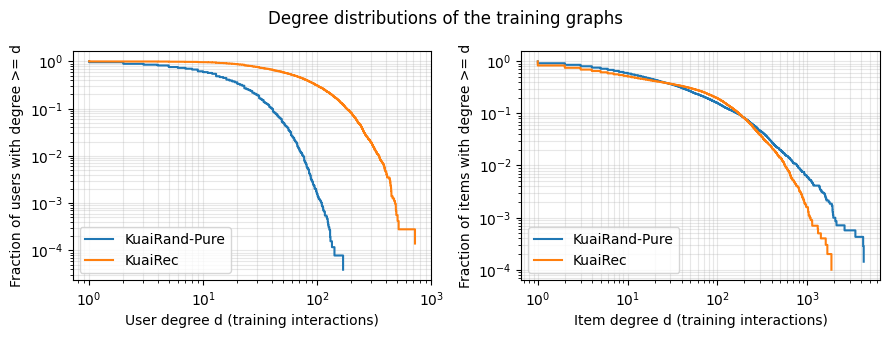

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.4))
for name, ds in main.items():
    for ax, deg in zip(axes, data.degrees(ds)):
        d = np.sort(deg[deg > 0])
        ax.step(d, 1 - np.arange(len(d)) / len(d), where="post", label=name)
for ax, side in zip(axes, ["User", "Item"]):
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_xlabel(f"{side} degree d (training interactions)")
    ax.set_ylabel(f"Fraction of {side.lower()}s with degree >= d")
    ax.grid(alpha=0.3, which="both"); ax.legend()
fig.suptitle("Degree distributions of the training graphs")
fig.tight_layout()
fig.savefig(os.path.join(RESULTS_DIR, "01_degree_distributions.png"), dpi=200, metadata={"Software": None})
plt.show()

## B4. Positive definition
### KuaiRand-Pure: candidate feedback signals
The three signals frequent enough to define a positive (rates from Part A), and the dataset each would give.

In [26]:
CANDIDATES = ["is_click", "is_like", "long_view"]
by_exposure = {"standard": std, "random": rnd}
signal_rates = pd.DataFrame({k: df[CANDIDATES].mean() for k, df in by_exposure.items()})
signal_rates.loc["exposures"] = [len(std), len(rnd)]
signal_rates

,standard,random
is_click,0.460,0.176
is_like,0.018,0.005
long_view,0.332,0.085
exposures,"1,436,609.000","1,186,059.000"


In [27]:
by_signal = {s: data.stats(data.load("kuairand", seed=0, positive=s)) for s in CANDIDATES}
pd.DataFrame(by_signal).T.drop(columns="name")

,users,items,train,val,test,test_unbiased,density,cold_users,cold_items
is_click,25689,7218,466490,54223,131436,194539,0.003,0,122
is_like,3433,3518,15248,2112,5526,2349,0.001,0,408
long_view,24916,6863,336808,40451,95922,90782,0.002,0,159


### KuaiRec: watch-ratio threshold
What each threshold gives in the big matrix. `>= 1` would double the graph and make LightGCN about 7 times slower per epoch; `>= 2` keeps a size similar to KuaiRand-Pure.

In [28]:
rows = {}
for t in [1.0, 1.5, 2.0, 3.0]:
    p = big[big.watch_ratio >= t].drop_duplicates(["user_id", "video_id"])
    n_u, n_i = p.user_id.nunique(), p.video_id.nunique()
    rows[f">= {t:g}"] = dict(positive_pairs=len(p), users=n_u, videos=n_i, density=len(p) / (n_u * n_i), per_user=len(p) / n_u)
pd.DataFrame(rows).T

,positive_pairs,users,videos,density,per_user
>= 1,"3,731,826.000","7,176.000","10,719.000",0.049,520.043
>= 1.5,"1,689,080.000","7,175.000","10,674.000",0.022,235.412
>= 2,"846,414.000","7,175.000","10,611.000",0.011,117.967
>= 3,"312,145.000","6,973.000","8,833.000",0.005,44.765


## B5. Repeated interactions
KuaiRand: a user can be shown the same video more than once; we keep one positive per (user, video). KuaiRec: a user can play the same video more than once; the pair is positive if any play reaches the threshold.

In [29]:
duplicates = {}
for k, df in by_exposure.items():
    pos = df[df.is_click == 1]
    unique = len(pos.drop_duplicates(["user_id", "video_id"]))
    duplicates[k] = dict(exposures=len(df), repeated_exposures=int(df.duplicated(["user_id", "video_id"]).sum()),
                         clicks=len(pos), unique_click_pairs=unique, removed=len(pos) - unique,
                         removed_share=(len(pos) - unique) / len(pos))
pd.DataFrame(duplicates).T

,exposures,repeated_exposures,clicks,unique_click_pairs,removed,removed_share
standard,"1,436,609.000","61,609.000","660,342.000","653,051.000","7,291.000",0.011
random,"1,186,059.000",53.000,"208,934.000","208,934.000",0.000,0.000


In [30]:
pair_max = big.groupby(["user_id", "video_id"]).watch_ratio.agg(["size", "max", "min"])
repeated = pair_max[pair_max["size"] > 1]
pd.Series({"pairs": len(pair_max), "pairs played more than once": len(repeated),
           "positive by max, negative by min": int(((repeated["max"] >= 2) & (repeated["min"] < 2)).sum()),
           "positive pairs": int((pair_max["max"] >= 2).sum())}).to_frame("count")

,count
pairs,10300969
pairs played more than once,1841544
"positive by max, negative by min",103863
positive pairs,846414


## B6. Biased vs. unbiased test
How popular are the test positives? Popularity of an item = its training degree. Then a most-popular baseline (recommend the items with the highest training degree to everyone) on both tests, and the best possible Recall@20 (a user with more than 20 positives cannot reach recall 1).

In [31]:
class MostPopular:
    """Scores every item by its training degree, the same for every user."""
    def __init__(self, ds):
        self.item_deg = torch.tensor(data.degrees(ds)[1], dtype=torch.float32)[:, None]
        self.n_users = ds["n_users"]
    def eval(self):
        pass
    def embeddings(self):
        return torch.ones(self.n_users, 1), self.item_deg

def test_popularity(ds, split):
    _, item_deg = data.degrees(ds)
    targets = np.concatenate(list(ds[split].values()))
    head = np.argsort(-item_deg)[: ds["n_items"] // 10]
    best = np.mean([min(len(v), 20) / len(v) for v in ds[split].values() if len(v)])
    return dict(users=len(ds[split]), positives=len(targets), mean_item_degree=float(item_deg[targets].mean()),
                share_in_top10pct_items=float(np.isin(targets, head).mean()), best_possible_recall=float(best))

split_compare = {}
for key, ds in datasets.items():
    for split, mask in [("test", ("train", "val")), ("test_unbiased", ("train", "val", "test"))]:
        m, _, _ = train.evaluate(MostPopular(ds), ds, split, mask_splits=mask)
        split_compare[(key, split)] = {**test_popularity(ds, split), "most_popular_recall": m["recall"], "most_popular_ndcg": m["ndcg"]}
pd.DataFrame(split_compare).T

users   positives  mean_item_degree  share_in_top10pct_items  best_possible_recall  most_popular_recall  most_popular_ndcg
kuairand test          25,689.000 131,436.000           530.306                    0.630                 0.998                0.114              0.076
         test_unbiased 21,515.000 194,539.000            88.780                    0.144                 0.957                0.007              0.005
kuairec  test           7,173.000 169,264.000           282.036                    0.558                 0.815                0.074              0.088
         test_unbiased  1,408.000 216,727.000           297.043                    0.551                 0.318                0.150              0.541

## Summary

- **Both datasets come from the same platform** (Kuaishou short videos), so differences between them are not a change of domain.
- **KuaiRand-Pure** is very sparse (0.25% training density, 18 positives per user) and its item popularity is highly concentrated. Its unbiased test uses randomly exposed videos, which are mostly unpopular: only 14% of unbiased positives fall on the 10% most popular items, against 63% of the biased test positives. A most-popular baseline drops from Recall@20 0.114 to 0.007.
- **KuaiRec** is denser (0.80%, 85 positives per user) and its unbiased test is a fully observed block of videos that are themselves popular. Popularity still pays there: the most-popular baseline reaches NDCG@20 of about 0.54 on the unbiased test. Recall@20 is capped (best possible about 0.32) because users have about 150 unbiased positives each, so NDCG@20 and the margin over most-popular are the numbers to compare.
- The two unbiased tests therefore remove different biases: KuaiRand's removes the recommender's choice of *which* videos are shown, KuaiRec's removes *missing* feedback on a fixed popular block. A model's advantage that survives both is a strong result; one that survives only KuaiRec's is likely driven by popularity.
- **KuaiRec's positive definition favours short videos:** 11% of plays of videos under 10 s reach a watch ratio of 2, against 0.2% for videos over 60 s. Under 10 s videos are 54% of all plays.

## B7. Save

In [32]:
out = dict(seed=0, positive=dict(kuairand="is_click == 1", kuairec="watch_ratio >= 2 (any play)"),
           datasets=stats, degrees=degree_stats, kuairand_signal_rates=signal_rates.to_dict(), kuairand_by_signal=by_signal,
           kuairand_duplicates=duplicates, split_compare={f"{k}|{s}": v for (k, s), v in split_compare.items()})
with open(os.path.join(RESULTS_DIR, "01_data_stats.json"), "w") as f:
    json.dump(out, f, indent=1, default=float)
print("saved", sorted(os.listdir(RESULTS_DIR)))

saved ['.gitkeep', '01_data_stats.json', '01_dataset_overview.csv', '01_degree_distributions.png', '01_kuairand_daily.png', '08_density_sweep_pilot.png', '08_density_sweep_pilot_gap.csv', '08_density_sweep_pilot_summary.csv']
